In [1]:
import numpy as np
import pandas as pd

In [2]:
diab=pd.read_csv("Diab.csv")
diab.head()

,Pat_Id,Gender,OGTT,DBP,BMI,Age,Diabetic
0,101,Male,176,90,33.7,58,Yes
1,102,Male,150,66,34.7,42,No
2,103,Male,73,50,23.0,21,No
3,104,Female,187,68,37.7,41,Yes
4,105,Female,100,88,46.8,31,No


In [3]:
diab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pat_Id    500 non-null    int64  
 1   Gender    500 non-null    object 
 2   OGTT      500 non-null    int64  
 3   DBP       500 non-null    int64  
 4   BMI       500 non-null    float64
 5   Age       500 non-null    int64  
 6   Diabetic  500 non-null    object 
dtypes: float64(1), int64(4), object(2)
memory usage: 27.5+ KB


In [4]:
diab.describe()

,Pat_Id,OGTT,DBP,BMI,Age
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,350.500000,120.664000,72.292000,32.361800,32.972000
std,144.481833,30.665483,11.716368,7.005166,11.741334
min,101.000000,44.000000,30.000000,18.200000,21.000000
25%,225.750000,98.750000,64.000000,27.400000,24.000000
50%,350.500000,116.000000,72.000000,32.000000,29.000000
75%,475.250000,140.000000,80.000000,36.325000,39.000000
max,600.000000,198.000000,122.000000,67.100000,81.000000


<Axes: >

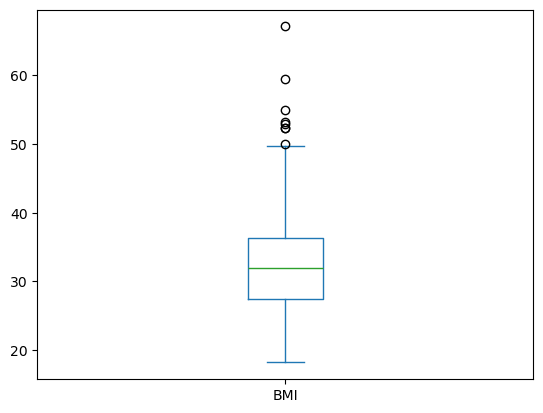

In [5]:
diab.BMI.plot(kind='box')

In [6]:
diab.drop('Pat_Id',axis=1,inplace=True)

In [7]:
diab_num=diab.select_dtypes(include='number')
diab_num.values

array([[176. ,  90. ,  33.7,  58. ],
       [150. ,  66. ,  34.7,  42. ],
       [ 73. ,  50. ,  23. ,  21. ],
       ...,
       [ 98. ,  60. ,  34.7,  22. ],
       [143. ,  86. ,  30.1,  23. ],
       [121. ,  78. ,  27.8,  38. ]], shape=(500, 4))

In [8]:
from sklearn.preprocessing import StandardScaler

sc=StandardScaler()

arr=diab_num.values

sc.fit(arr)

,copy,True
,with_mean,True
,with_std,True


In [9]:
arr

array([[176. ,  90. ,  33.7,  58. ],
       [150. ,  66. ,  34.7,  42. ],
       [ 73. ,  50. ,  23. ,  21. ],
       ...,
       [ 98. ,  60. ,  34.7,  22. ],
       [143. ,  86. ,  30.1,  23. ],
       [121. ,  78. ,  27.8,  38. ]], shape=(500, 4))

In [10]:
sc.transform(arr)

array([[ 1.80631165,  1.51290352,  0.19122178,  2.13374943],
       [ 0.9576037 , -0.53756432,  0.33411654,  0.76967755],
       [-1.55587752, -1.90454288, -1.33775222, -1.02066678],
       ...,
       [-0.73981219, -1.05018128,  0.33411654, -0.93541229],
       [ 0.72910541,  1.17115888, -0.32319938, -0.8501578 ],
       [ 0.01096792,  0.4876696 , -0.65185734,  0.42865959]],
      shape=(500, 4))

In [11]:
X_sc=sc.fit_transform(diab_num)
X_sc

array([[ 1.80631165,  1.51290352,  0.19122178,  2.13374943],
       [ 0.9576037 , -0.53756432,  0.33411654,  0.76967755],
       [-1.55587752, -1.90454288, -1.33775222, -1.02066678],
       ...,
       [-0.73981219, -1.05018128,  0.33411654, -0.93541229],
       [ 0.72910541,  1.17115888, -0.32319938, -0.8501578 ],
       [ 0.01096792,  0.4876696 , -0.65185734,  0.42865959]],
      shape=(500, 4))

In [12]:
from sklearn.preprocessing import MinMaxScaler

mm=MinMaxScaler()

arr=diab_num.values

X_mm=mm.fit_transform(arr)
X_mm

array([[0.85714286, 0.65217391, 0.31697342, 0.61666667],
       [0.68831169, 0.39130435, 0.33742331, 0.35      ],
       [0.18831169, 0.2173913 , 0.09815951, 0.        ],
       ...,
       [0.35064935, 0.32608696, 0.33742331, 0.01666667],
       [0.64285714, 0.60869565, 0.24335378, 0.03333333],
       [0.5       , 0.52173913, 0.19631902, 0.28333333]], shape=(500, 4))

# Encoding

In [13]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

#diab['Gender']=le.fit_transform(diab['Gender'])
diab['Diabetic']=le.fit_transform(diab['Diabetic'])

In [14]:
diab.head()

,Gender,OGTT,DBP,BMI,Age,Diabetic
0,Male,176,90,33.7,58,1
1,Male,150,66,34.7,42,0
2,Male,73,50,23.0,21,0
3,Female,187,68,37.7,41,1
4,Female,100,88,46.8,31,0


In [30]:
from sklearn.preprocessing import OneHotEncoder
oe=OneHotEncoder()

gender=oe.fit_transform(diab[['Gender']]).toarray().astype('int')
encoded=pd.DataFrame(gender,columns=['Female','Male'])
encoded.head()


,Female,Male
0,0,1
1,0,1
2,0,1
3,1,0
4,1,0


In [16]:
final=diab.join(encoded)

In [17]:

final.head()

,Gender,OGTT,DBP,BMI,Age,Diabetic,Female,Male
0,Male,176,90,33.7,58,1,0,1
1,Male,150,66,34.7,42,0,0,1
2,Male,73,50,23.0,21,0,0,1
3,Female,187,68,37.7,41,1,1,0
4,Female,100,88,46.8,31,0,1,0


In [18]:
final.drop('Gender',axis=1,inplace=True)

In [19]:
final.head()

,OGTT,DBP,BMI,Age,Diabetic,Female,Male
0,176,90,33.7,58,1,0,1
1,150,66,34.7,42,0,0,1
2,73,50,23.0,21,0,0,1
3,187,68,37.7,41,1,1,0
4,100,88,46.8,31,0,1,0


# Ordinal Encoding

In [20]:
import pandas as pd
diab=pd.read_csv("Diab.csv")

In [21]:

diab.head()

,Pat_Id,Gender,OGTT,DBP,BMI,Age,Diabetic
0,101,Male,176,90,33.7,58,Yes
1,102,Male,150,66,34.7,42,No
2,103,Male,73,50,23.0,21,No
3,104,Female,187,68,37.7,41,Yes
4,105,Female,100,88,46.8,31,No


In [22]:
pd.get_dummies(diab['Gender'],dtype=int,drop_first=True)   # drop_first = for dropping one column bcz we are loosing any information

,Male
0,1
1,1
2,1
3,0
4,0
...,...
495,1
496,0
497,0
498,0


In [23]:
diab.Diabetic[diab.Diabetic == "Yes"]=1
diab.Diabetic[diab.Diabetic == "No"]=0

C:\Users\ExcelR Trainers\AppData\Local\Temp\ipykernel_10332\2641492765.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  diab.Diabetic[diab.Diabetic == "Yes"]=1
C:\Users\ExcelR Trainers\AppData\Local\Temp\ipykernel_10332\2641492765.py:1: S

In [24]:
diab.head()

,Pat_Id,Gender,OGTT,DBP,BMI,Age,Diabetic
0,101,Male,176,90,33.7,58,1
1,102,Male,150,66,34.7,42,0
2,103,Male,73,50,23.0,21,0
3,104,Female,187,68,37.7,41,1
4,105,Female,100,88,46.8,31,0


In [25]:
import pandas as pd
diab=pd.read_csv("Diab.csv")

In [26]:
diab['Gender'].map({"Female":1,"Male":2})

0      2
1      2
2      2
3      1
4      1
      ..
495    2
496    1
497    1
498    1
499    2
Name: Gender, Length: 500, dtype: int64